# CA1 – Statistical Analysis of Credit Card Default Data

**Module:** Stats for Data Analytics  
**Programme:** Higher Diploma in Data Analytics in Business  
**Student ID:** 2026328  
**Assignment:** CA1  
**GitHub Repository:** https://github.com/2026328-Dashzeveg-Purevtogtokh/Statistical-Techniques-Sep26

This notebook analyses the **Default of Credit Card Clients** dataset using descriptive statistics and three probability distributions: **Binomial, Poisson, and Normal**.


## 1. Import Libraries

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import binom, poisson, norm

plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.25})
pd.set_option("display.max_columns", 30)

## 2. Load Dataset

In [12]:
rawData = pd.read_excel("data/default of credit card clients.xls",header=1)
df = rawData.copy()
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [13]:
df.columns.tolist()

['ID',
 'LIMIT_BAL',
 'SEX',
 'EDUCATION',
 'MARRIAGE',
 'AGE',
 'PAY_0',
 'PAY_2',
 'PAY_3',
 'PAY_4',
 'PAY_5',
 'PAY_6',
 'BILL_AMT1',
 'BILL_AMT2',
 'BILL_AMT3',
 'BILL_AMT4',
 'BILL_AMT5',
 'BILL_AMT6',
 'PAY_AMT1',
 'PAY_AMT2',
 'PAY_AMT3',
 'PAY_AMT4',
 'PAY_AMT5',
 'PAY_AMT6',
 'default payment next month']

In [14]:
df.columns = df.columns.str.strip().str.lower()
print(df.columns.tolist())

['id', 'limit_bal', 'sex', 'education', 'marriage', 'age', 'pay_0', 'pay_2', 'pay_3', 'pay_4', 'pay_5', 'pay_6', 'bill_amt1', 'bill_amt2', 'bill_amt3', 'bill_amt4', 'bill_amt5', 'bill_amt6', 'pay_amt1', 'pay_amt2', 'pay_amt3', 'pay_amt4', 'pay_amt5', 'pay_amt6', 'default payment next month']


In [15]:
df.columns

Index(['id', 'limit_bal', 'sex', 'education', 'marriage', 'age', 'pay_0',
       'pay_2', 'pay_3', 'pay_4', 'pay_5', 'pay_6', 'bill_amt1', 'bill_amt2',
       'bill_amt3', 'bill_amt4', 'bill_amt5', 'bill_amt6', 'pay_amt1',
       'pay_amt2', 'pay_amt3', 'pay_amt4', 'pay_amt5', 'pay_amt6',
       'default payment next month'],
      dtype='object')

In [ ]:
# Rename target value 
df.columns = [col.strip().lower().replace(" ", "_") for col in df.columns]
df = df.rename(columns={"default_payment_next_month": "default"})

In [22]:
df = df.applymap(lambda s: s.lower() if type(s) == str else s)

## 3. Dataset Overview and Data Quality Check
Before analysis, the dataset is checked for size, data types, missing values, and duplicate rows.

In [24]:
print("Dataset shape:", df.shape)
print("\nMissing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nData types:")
df.dtypes

Dataset shape: (30000, 25)

Missing values: 0
Duplicate rows: 0

Data types:


id           int64
limit_bal    int64
sex          int64
education    int64
marriage     int64
age          int64
pay_0        int64
pay_2        int64
pay_3        int64
pay_4        int64
pay_5        int64
pay_6        int64
bill_amt1    int64
bill_amt2    int64
bill_amt3    int64
bill_amt4    int64
bill_amt5    int64
bill_amt6    int64
pay_amt1     int64
pay_amt2     int64
pay_amt3     int64
pay_amt4     int64
pay_amt5     int64
pay_amt6     int64
default      int64
dtype: object

In [25]:
df[["sex", "education", "marriage", "default"]].nunique().to_frame("Number of categories")

,Number of categories
sex,2
education,7
marriage,4
default,2


**Interpretation:** The dataset contains 30,000 customer records and 25 columns. There are no missing values or exact duplicate rows. Therefore, the dataset is already relatively clean and requires only limited data cleaning.

## 4. Variable Classification
The analysis uses both categorical and numerical variables. The repayment-status columns contain numerical codes, but they are treated as ordinal variables rather than continuous variables.

In [26]:
categorical_cols = ["sex", "education", "marriage", "default"]

numerical_cols = [
    "limit_bal", "age",
    "bill_amt1", "bill_amt2", "bill_amt3", "bill_amt4", "bill_amt5", "bill_amt6",
    "pay_amt1", "pay_amt2", "pay_amt3", "pay_amt4", "pay_amt5", "pay_amt6"
]

print("Categorical variables:", categorical_cols)
print("\nSelected numerical variables:", numerical_cols)

Categorical variables: ['sex', 'education', 'marriage', 'default']

Selected numerical variables: ['limit_bal', 'age', 'bill_amt1', 'bill_amt2', 'bill_amt3', 'bill_amt4', 'bill_amt5', 'bill_amt6', 'pay_amt1', 'pay_amt2', 'pay_amt3', 'pay_amt4', 'pay_amt5', 'pay_amt6']


## 5. Descriptive Statistics
Descriptive statistics are used to understand the centre, spread, and distribution of the selected continuous variables.

In [27]:
selected_numeric = ["limit_bal", "age", "bill_amt1", "pay_amt1"]

df[selected_numeric].describe().T

,count,mean,std,min,25%,50%,75%,max
limit_bal,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.0,1000000.0
age,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.0,79.0
bill_amt1,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.0,964511.0
pay_amt1,30000.0,5663.580500,16563.280354,0.0,1000.00,2100.0,5006.0,873552.0


In [28]:
summary_stats = pd.DataFrame({
    "Mean": df[selected_numeric].mean(),
    "Median": df[selected_numeric].median(),
    "Standard Deviation": df[selected_numeric].std(),
    "Minimum": df[selected_numeric].min(),
    "Maximum": df[selected_numeric].max(),
    "Skewness": df[selected_numeric].skew()
})

summary_stats.round(2)

,Mean,Median,Standard Deviation,Minimum,Maximum,Skewness
limit_bal,167484.32,140000.0,129747.66,10000,1000000,0.99
age,35.49,34.0,9.22,21,79,0.73
bill_amt1,51223.33,22381.5,73635.86,-165580,964511,2.66
pay_amt1,5663.58,2100.0,16563.28,0,873552,14.67


**Interpretation:** The average credit limit is about 167,484, while the median is 140,000. This suggests that the distribution is positively skewed. Customer age has a mean of about 35.49 years and a median of 34 years, which also shows moderate positive skewness. bill_amt1 and especially pay_amt1 have much stronger positive skewness. This means that a small number of very high financial values increase the average.

In [29]:
default_counts = df["default"].value_counts().sort_index()
default_percent = (df["default"].value_counts(normalize=True).sort_index() * 100).round(2)

pd.DataFrame({"Count": default_counts, "Percentage": default_percent})

,Count,Percentage
0,23364,77.88
1,6636,22.12


## 6. Data Visualisation
The following graphs support the descriptive statistics and help to explain the distribution and balance of the main variables.

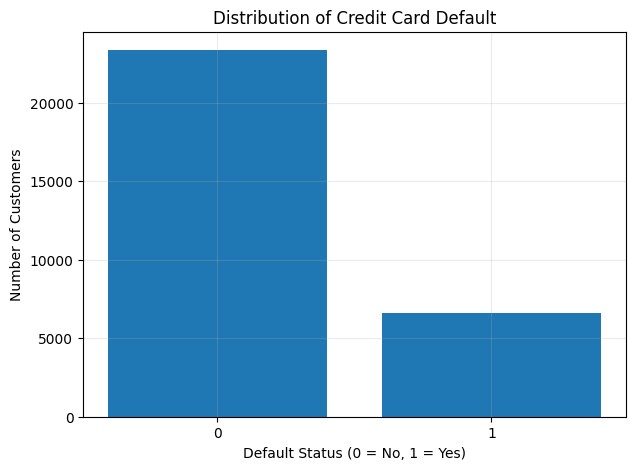

In [30]:
plt.figure(figsize=(7, 5))
counts = df["default"].value_counts().sort_index()
plt.bar(counts.index.astype(str), counts.values)
plt.title("Distribution of Credit Card Default")
plt.xlabel("Default Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

The default graph shows that most customers did not default. About 22.12% of customers defaulted, while 77.88% did not. Since this variable has only two possible outcomes, it is suitable for Binomial analysis.

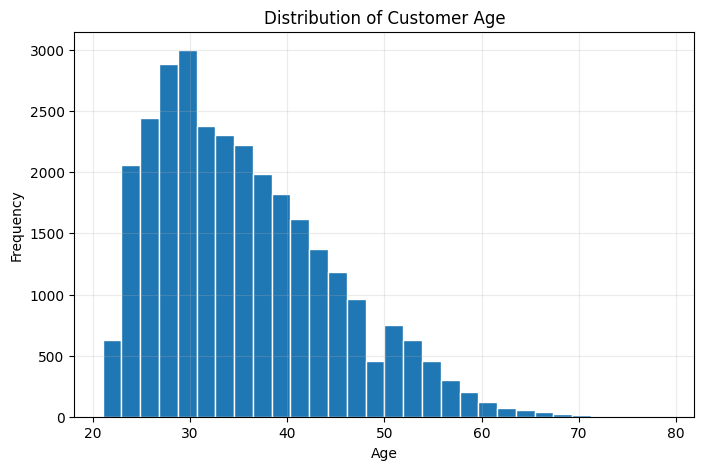

In [31]:
plt.figure(figsize=(8, 5))
plt.hist(df["age"], bins=30, edgecolor="white")
plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

The age distribution is mainly concentrated between the late twenties and early forties, with a longer tail on the right side. This is consistent with the positive skewness value of about 0.73.

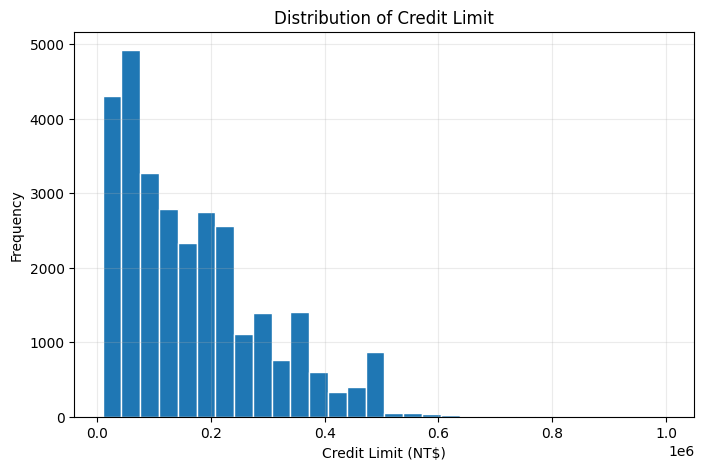

In [32]:
plt.figure(figsize=(8, 5))
plt.hist(df["limit_bal"], bins=30, edgecolor="white")
plt.title("Distribution of Credit Limit")
plt.xlabel("Credit Limit (NT$)")
plt.ylabel("Frequency")
plt.show()

The credit-limit distribution is positively skewed. Most customers have low to medium credit limits, while only a small number of customers have very high credit limits.

## 7. Binomial Distribution
The `default` variable is suitable for a Binomial distribution because each customer has two possible outcomes: default (`1`) or no default (`0`).

In [33]:
p_default = df["default"].mean()
print(f"Observed probability of default: {p_default:.4f} ({p_default*100:.2f}%)")

n = 10
k = 3
probability_3_defaults = binom.pmf(k, n, p_default)
expected_10 = n * p_default

print(f"Probability of exactly 3 defaults among 10 customers: {probability_3_defaults:.4f}")
print(f"Expected defaults among 10 customers: {expected_10:.3f}")

Observed probability of default: 0.2212 (22.12%)
Probability of exactly 3 defaults among 10 customers: 0.2257
Expected defaults among 10 customers: 2.212


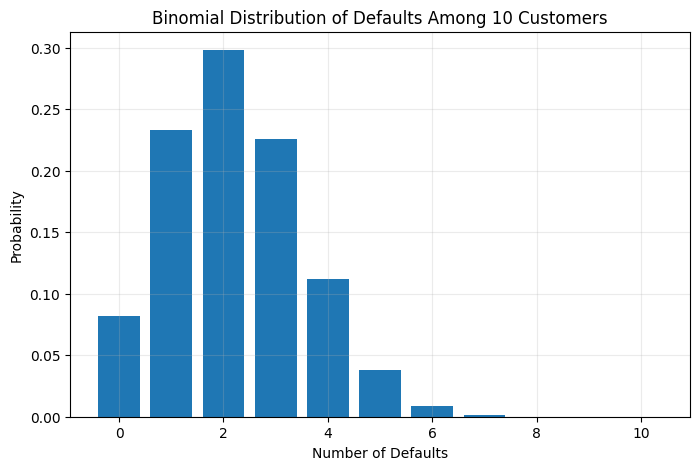

In [34]:
x = np.arange(0, n + 1)
plt.figure(figsize=(8, 5))
plt.bar(x, binom.pmf(x, n, p_default))
plt.title("Binomial Distribution of Defaults Among 10 Customers")
plt.xlabel("Number of Defaults")
plt.ylabel("Probability")
plt.show()

For a sample of 10 customers, the expected number of defaults is 2.212. The most likely outcomes are around two or three defaults. This is consistent with the observed probability of default.

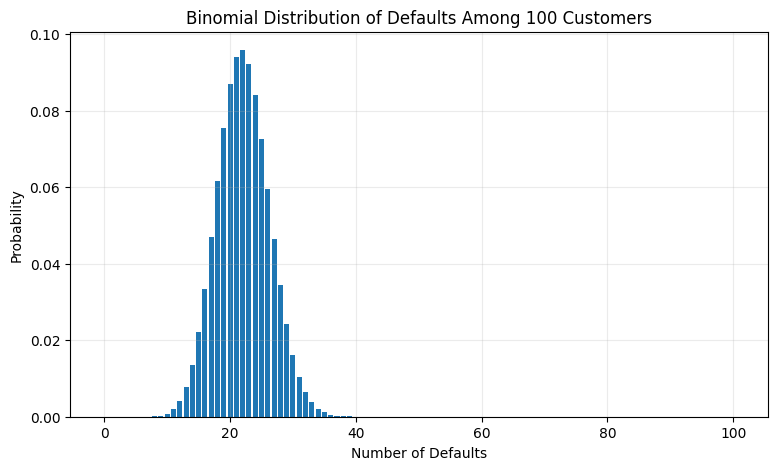

Expected defaults among 100 customers: 22.12


In [35]:
n_large = 100
x_large = np.arange(0, n_large + 1)
prob_large = binom.pmf(x_large, n_large, p_default)

plt.figure(figsize=(9, 5))
plt.bar(x_large, prob_large)
plt.title("Binomial Distribution of Defaults Among 100 Customers")
plt.xlabel("Number of Defaults")
plt.ylabel("Probability")
plt.show()

print(f"Expected defaults among 100 customers: {n_large*p_default:.2f}")

When the sample size increases to 100, the distribution becomes smoother and more bell-shaped, with an expected value of 22.12 defaults. This shows that a Binomial distribution can become similar to a Normal distribution when the sample size is large.

## 8. Poisson Distribution
A count variable is created from the six repayment-status months. A positive repayment-status code is treated as a late-payment month.

In [36]:
payment_status_cols = ["pay_0", "pay_2", "pay_3", "pay_4", "pay_5", "pay_6"]

df["late_payment_count"] = (df[payment_status_cols] > 0).sum(axis=1)

df["late_payment_count"].value_counts().sort_index().to_frame("Customers")

,Customers
0,19931
1,4426
2,1899
3,1154
4,951
5,298
6,1341


In [37]:
lambda_late = df["late_payment_count"].mean()
prob_2_late = poisson.pmf(2, mu=lambda_late)

print(f"Average number of late-payment months (lambda): {lambda_late:.4f}")
print(f"Poisson probability of exactly 2 late-payment months: {prob_2_late:.4f}")

Average number of late-payment months (lambda): 0.8342
Poisson probability of exactly 2 late-payment months: 0.1511


In [38]:
x = np.arange(0, 7)
observed = df["late_payment_count"].value_counts(normalize=True).sort_index().reindex(x, fill_value=0)
poisson_probs = poisson.pmf(x, mu=lambda_late)

comparison = pd.DataFrame({
    "Late Payments": x,
    "Observed": observed.values,
    "Poisson": poisson_probs
})
comparison.round(4)

,Late Payments,Observed,Poisson
0,0,0.6644,0.4342
1,1,0.1475,0.3622
2,2,0.0633,0.1511
3,3,0.0385,0.0420
4,4,0.0317,0.0088
5,5,0.0099,0.0015
6,6,0.0447,0.0002


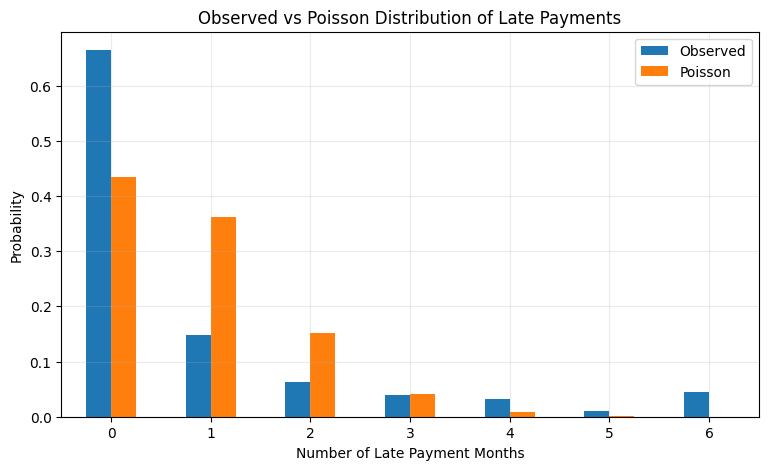

In [39]:
comparison.plot(
    x="Late Payments",
    y=["Observed", "Poisson"],
    kind="bar",
    figsize=(9, 5)
)
plt.title("Observed vs Poisson Distribution of Late Payments")
plt.xlabel("Number of Late Payment Months")
plt.ylabel("Probability")
plt.xticks(rotation=0)
plt.show()

**Interpretation:** The late-payment data does not closely match the Poisson model. There are more customers with zero late payments and six late-payment months than the model predicted. This shows that the data may not fully follow the assumptions of the Poisson model. The number of late payments may change over time, and the months may not be completely independent. However, the Poisson model is still useful for comparing count data.

## 9. Normal Distribution
Customer age was selected because it is a continuous variable and its distribution is less skewed than the selected financial variables.

In [40]:
age_mean = df["age"].mean()
age_std = df["age"].std()

print(f"Mean age: {age_mean:.2f}")
print(f"Standard deviation: {age_std:.2f}")
print(f"Skewness: {df['age'].skew():.2f}")

Mean age: 35.49
Standard deviation: 9.22
Skewness: 0.73


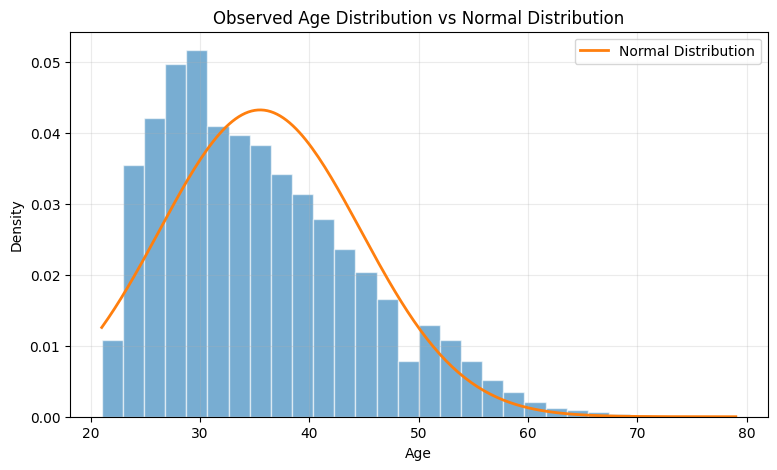

In [41]:
plt.figure(figsize=(9, 5))
plt.hist(df["age"], bins=30, density=True, alpha=0.6, edgecolor="white")

x = np.linspace(df["age"].min(), df["age"].max(), 200)
normal_curve = norm.pdf(x, loc=age_mean, scale=age_std)
plt.plot(x, normal_curve, linewidth=2, label="Normal Distribution")

plt.title("Observed Age Distribution vs Normal Distribution")
plt.xlabel("Age")
plt.ylabel("Density")
plt.legend()
plt.show()

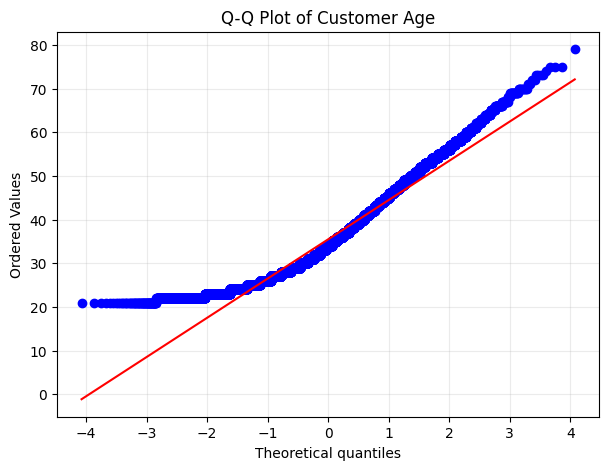

In [42]:
plt.figure(figsize=(7, 5))
stats.probplot(df["age"], dist="norm", plot=plt)
plt.title("Q-Q Plot of Customer Age")
plt.show()

The histogram and Q-Q plot show that customer age is not perfectly normally distributed. Most of the values in the middle are close to the normal distribution. However, the values at both ends are different from the normal pattern. The distribution also shows a slight positive skew.

In [43]:
prob_age_30_40 = (
    norm.cdf(40, loc=age_mean, scale=age_std)
    - norm.cdf(30, loc=age_mean, scale=age_std)
)
actual_age_30_40 = df["age"].between(30, 40).mean()

print(f"Normal model probability, age 30-40: {prob_age_30_40:.4f} ({prob_age_30_40*100:.2f}%)")
print(f"Observed proportion, age 30-40: {actual_age_30_40:.4f} ({actual_age_30_40*100:.2f}%)")

Normal model probability, age 30-40: 0.4120 (41.20%)
Observed proportion, age 30-40: 0.4036 (40.36%)


The Normal model estimates that 41.20% of customers are aged between 30 and 40, while the actual value is 40.36%. These values are very close. This means the Normal model gives a reasonable estimate for this age group, although the overall age distribution is not perfectly normal.

## 10. Comparison of Probability Distributions
The final section compares the three distributions and explains why each variable was selected.

In [23]:
distribution_summary = pd.DataFrame({
    "Distribution": ["Binomial", "Poisson", "Normal"],
    "Variable": ["default", "late_payment_count", "age"],
    "Variable Type": ["Binary discrete", "Count discrete", "Continuous"],
    "Main Parameter": [
        f"p = {p_default:.4f}",
        f"lambda = {lambda_late:.4f}",
        f"mean = {age_mean:.2f}, std = {age_std:.2f}"
    ]
})

distribution_summary

,Distribution,Variable,Variable Type,Main Parameter
0,Binomial,default,Binary discrete,p = 0.2212
1,Poisson,late_payment_count,Count discrete,lambda = 0.8342
2,Normal,age,Continuous,"mean = 35.49, std = 9.22"


The Binomial distribution is suitable for default because this variable has two possible outcomes: default or no default. The Poisson distribution can be used to analyse late_payment_count because it represents count data. However, the Poisson model does not closely match the observed values. The Normal distribution is applied to age because age is a continuous variable and its distribution is less skewed than the selected financial variables.

The default variable is not suitable for a direct Normal distribution because it only contains the values 0 and 1. The late_payment_count variable is also discrete and ranges from 0 to 6, so the Normal distribution is not a good choice for this variable. However, a Binomial distribution can become similar to a Normal distribution when the number of trials is large.

Overall, this analysis shows that the choice of distribution depends on the type and characteristics of each variable. Therefore, the same probability distribution should not be used for all variables.

## 11. Conclusion
The dataset contains both categorical and numerical variables. The descriptive statistics showed that several financial variables were positively skewed, while age was closer to a Normal distribution. The Binomial distribution was suitable for the binary default variable, and the large-sample example showed how it can become more bell-shaped. The Poisson model was useful for comparing late-payment counts, but it did not closely match the observed data. The Normal distribution gave a reasonable estimate for the central part of the age data. Overall, these results show that the probability distribution should be selected based on the type and shape of each variable.